            Penjualan  Moving_Average
2026-01-01         10             NaN
2026-01-02         20       20.000000
2026-01-03         30       21.666667
2026-01-04         15       23.333333
2026-01-05         25       26.666667
2026-01-06         40       33.333333
2026-01-07         35       41.666667
2026-01-08         50       43.333333
2026-01-09         45       51.666667
2026-01-10         60             NaN


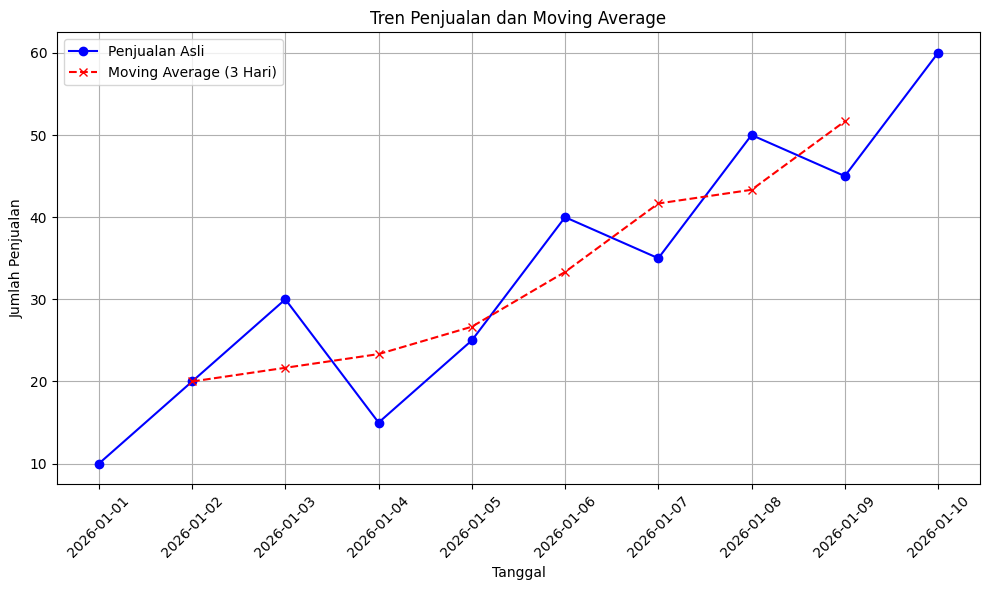

In [68]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

hari = pd.date_range('2026-01-01', periods=10)
penjualan = [10, 20, 30, 15, 25, 40, 35, 50, 45, 60]
df_tren = pd.DataFrame({'Penjualan': penjualan}, index=hari)

df_tren['Moving_Average'] = df_tren['Penjualan'].rolling(
    window=3,
    center=True
).mean()

print(df_tren)

plt.figure(figsize=(10, 6))
plt.plot(df_tren.index, df_tren['Penjualan'], marker='o', label='Penjualan Asli', color='blue')
plt.plot(df_tren.index, df_tren['Moving_Average'], marker='x', linestyle='--', label='Moving Average (3 Hari)', color='red')

plt.title('Tren Penjualan dan Moving Average')
plt.xlabel('Tanggal')
plt.ylabel('Jumlah Penjualan')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


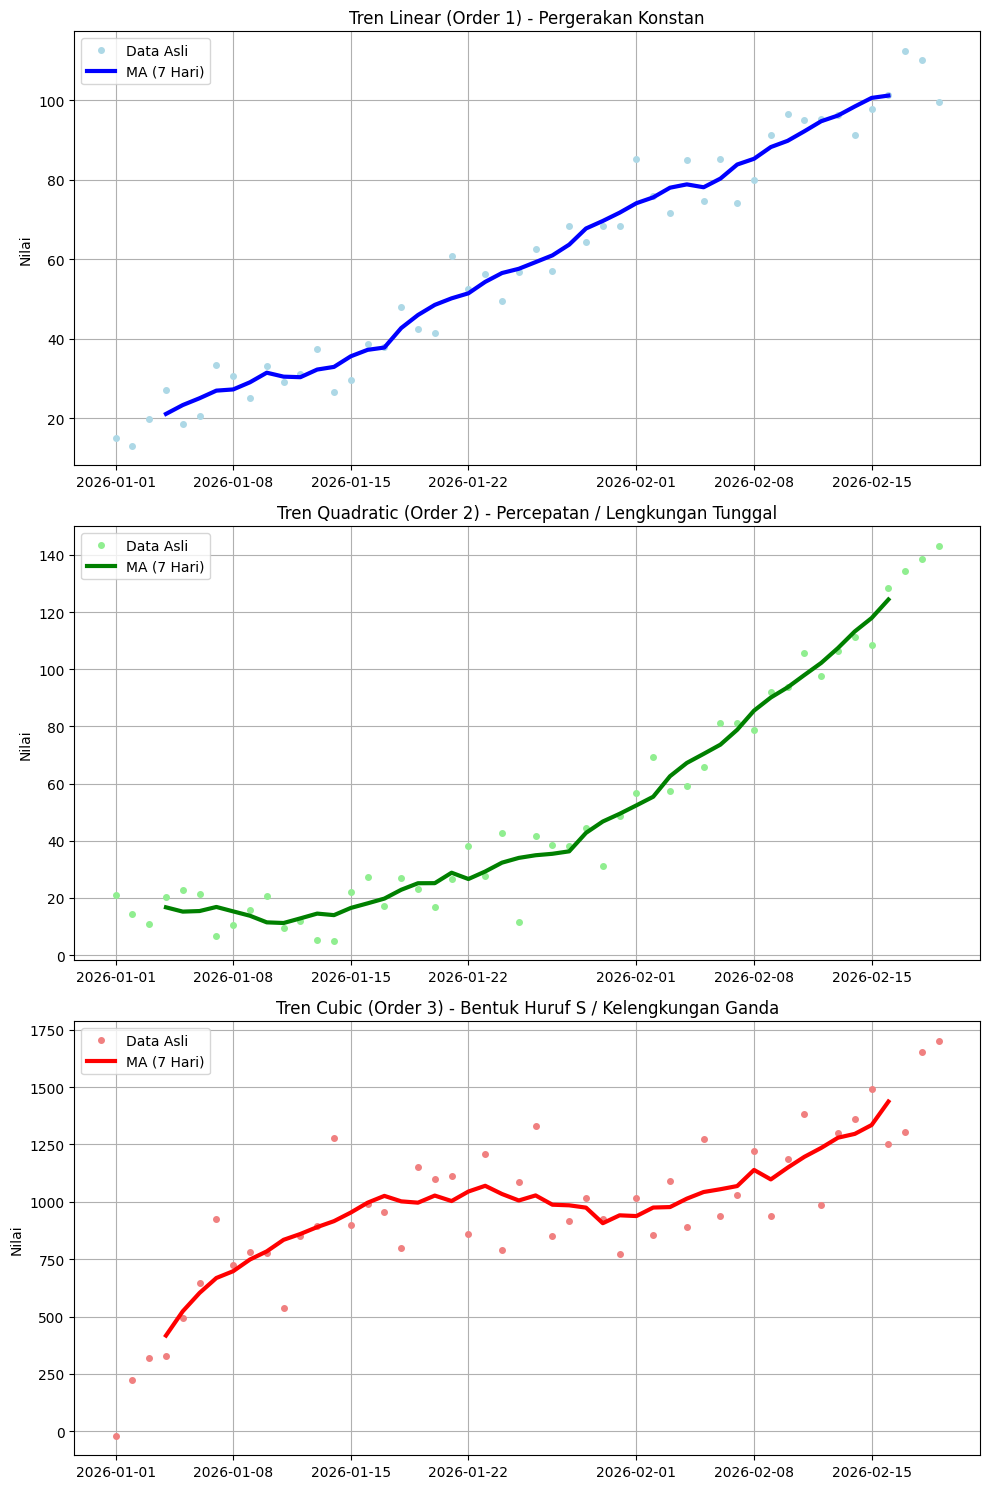

In [69]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Data Simulasi (50 Hari)
np.random.seed(42)
hari = pd.date_range('2026-01-01', periods=50)
t = np.arange(1, 51)

# Persamaan Linear 
linear_data = 2 * t + 10 + np.random.normal(0, 6, 50)

# Persamaan Quadratic
quad_data = 0.08 * (t**2) - 1.5 * t + 20 + np.random.normal(0, 8, 50)

# Persamaan Cubic
t_shifted = t - 25 
cubic_data = 0.05 * (t_shifted**3) - 0.2 * (t_shifted**2) + np.random.normal(0, 150, 50) + 1000

# Perhitungan Moving Average (Window = 7 Hari)
df = pd.DataFrame({'Linear': linear_data, 'Quadratic': quad_data, 'Cubic': cubic_data}, index=hari)
df['MA_Linear'] = df['Linear'].rolling(window=7, center=True).mean()
df['MA_Quadratic'] = df['Quadratic'].rolling(window=7, center=True).mean()
df['MA_Cubic'] = df['Cubic'].rolling(window=7, center=True).mean()

# Visualisasi
fig, axes = plt.subplots(3, 1, figsize=(10, 15))

# Konfigurasi Grafik Linear
axes[0].plot(df.index, df['Linear'], marker='o', markersize=4, linestyle='', color='lightblue', label='Data Asli')
axes[0].plot(df.index, df['MA_Linear'], color='blue', linewidth=3, label='MA (7 Hari)')
axes[0].set_title('Tren Linear (Order 1) - Pergerakan Konstan')

# Konfigurasi Grafik Quadratic
axes[1].plot(df.index, df['Quadratic'], marker='o', markersize=4, linestyle='', color='lightgreen', label='Data Asli')
axes[1].plot(df.index, df['MA_Quadratic'], color='green', linewidth=3, label='MA (7 Hari)')
axes[1].set_title('Tren Quadratic (Order 2) - Percepatan / Lengkungan Tunggal')

# Konfigurasi Grafik Cubic
axes[2].plot(df.index, df['Cubic'], marker='o', markersize=4, linestyle='', color='lightcoral', label='Data Asli')
axes[2].plot(df.index, df['MA_Cubic'], color='red', linewidth=3, label='MA (7 Hari)')
axes[2].set_title('Tren Cubic (Order 3) - Bentuk Huruf S / Kelengkungan Ganda')

for ax in axes:
    ax.tick_params(axis='x', rotation=0)
    ax.grid(True)
    ax.legend()
    ax.set_ylabel('Nilai')

plt.tight_layout()
plt.show()

In [70]:
from statsmodels.tsa.deterministic import DeterministicProcess
import pandas as pd
import numpy as np

dp = DeterministicProcess(
    index=df.index, 
    constant=True,       
    order=2,             
    drop=True            
)

X_tren = dp.in_sample()

print("=== Fitur Tren Kuadratik (Order 2) ===")
print(X_tren.head())

=== Fitur Tren Kuadratik (Order 2) ===
            const  trend  trend_squared
2026-01-01    1.0    1.0            1.0
2026-01-02    1.0    2.0            4.0
2026-01-03    1.0    3.0            9.0
2026-01-04    1.0    4.0           16.0
2026-01-05    1.0    5.0           25.0


In [71]:
waktu = pd.date_range(start='2026-03-14', periods=4, freq='D')
df_kalender = pd.DataFrame(index=waktu)

# 1. Ekstraksi Fitur Numerik
df_kalender['Bulan'] = df_kalender.index.month
df_kalender['Tanggal'] = df_kalender.index.day
df_kalender['Hari_Ke'] = df_kalender.index.dayofweek

# 2. Ekstraksi Fitur Biner (Kondisional)
# Jika Hari_Ke adalah 5 (Sabtu) atau 6 (Minggu), berikan nilai 1, sisanya 0
df_kalender['Akhir_Pekan'] = np.where(df_kalender['Hari_Ke'] >= 5, 1, 0)

print("=== Fitur Kalender ===")
print(df_kalender)

=== Fitur Kalender ===
            Bulan  Tanggal  Hari_Ke  Akhir_Pekan
2026-03-14      3       14        5            1
2026-03-15      3       15        6            1
2026-03-16      3       16        0            0
2026-03-17      3       17        1            0


In [72]:
import pandas as pd
import numpy as np

data_mentah = {
    'Tanggal_Teks': ['2026-03-01', '03/02/2026', 'March 3, 2026', '2026-03-05', '2026-03-06'], # Tgl 4 Hilang
    'Penjualan': [150, 160, 155, 170, 165]
}
df = pd.DataFrame(data_mentah)

print("=== 1. Tipe Data Awal ===")
print(df.dtypes)
df.head()

=== 1. Tipe Data Awal ===
Tanggal_Teks    object
Penjualan        int64
dtype: object


,Tanggal_Teks,Penjualan
0,2026-03-01,150
1,03/02/2026,160
2,"March 3, 2026",155
3,2026-03-05,170
4,2026-03-06,165


In [73]:
# pd.to_datetime dapat membaca berbagai format teks menjadi format baku YYYY-MM-DD
df['Waktu_Baku'] = pd.to_datetime(df['Tanggal_Teks'], format='mixed')

# Pindahkan kolom waktu menjadi urutan baris utama (index), lalu buang kolom teks aslinya
df = df.set_index('Waktu_Baku')
df = df.drop(columns=['Tanggal_Teks'])

print("\n=== 2. Data Setelah Konversi dan Set Index ===")
print(df)
print("Tipe Indeks saat ini:", type(df.index))


=== 2. Data Setelah Konversi dan Set Index ===
            Penjualan
Waktu_Baku           
2026-03-01        150
2026-03-02        160
2026-03-03        155
2026-03-05        170
2026-03-06        165
Tipe Indeks saat ini: <class 'pandas.core.indexes.datetimes.DatetimeIndex'>


In [74]:
# Cek frekuensi saat ini, jika 'None' = sistem belum yakin polanya akibat tanggal yang hilang
print(f"\nFrekuensi awal: {df.index.freq}") 

# Atur frekuensi menjadi Harian ('D') menggunakan .asfreq()
df = df.asfreq('D')

print("\n=== 3. Data Setelah Penetapan Frekuensi ('D') ===")
print(f"\nFrekuensi akhir: {df.index.freq}") 
print(df)
# Perhatikan bahwa baris '2026-03-04' kini muncul dengan nilai NaN (Kosong)


Frekuensi awal: None

=== 3. Data Setelah Penetapan Frekuensi ('D') ===

Frekuensi akhir: <Day>
            Penjualan
Waktu_Baku           
2026-03-01      150.0
2026-03-02      160.0
2026-03-03      155.0
2026-03-04        NaN
2026-03-05      170.0
2026-03-06      165.0


In [75]:
df['Penjualan'] = df['Penjualan'].ffill() 

print("\n=== 4. Data Final Siap Masuk Algoritma ===")
print(df)
print(f"Frekuensi Final: {df.index.freq}") # Output: <Day>


=== 4. Data Final Siap Masuk Algoritma ===
            Penjualan
Waktu_Baku           
2026-03-01      150.0
2026-03-02      160.0
2026-03-03      155.0
2026-03-04      155.0
2026-03-05      170.0
2026-03-06      165.0
Frekuensi Final: <Day>
